# 4. Walk-forward : un modèle qui ne voit jamais le futur

Jusqu'ici, il restait deux biais : le HMM et le `StandardScaler` étaient ajustés sur toute la période. Le walk-forward simule l'utilisation du modèle en temps réel. Pour chaque année de 2010 à aujourd'hui :

1. on ne garde que les données jusqu'au 31 décembre de l'année précédente ;
2. on ajuste le scaler sur ce passé seulement (fenêtre croissante) ;
3. on entraîne un HMM à 4 états et on ordonne ses états par volatilité ;
4. on filtre jour par jour l'année de test.

La période d'entraînement initiale (2000–2009) contient deux vraies crises, la bulle internet et 2008 : le modèle sait à quoi ressemble un régime de crise dès la première année de test.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Remonte jusqu'au dossier qui contient src/, quel que soit l'endroit d'où on lance
root = Path.cwd()
while not (root / "src").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
DATA = root / "data"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

from src.features import hmm_features
from src.models import STATE_NAMES, filtered_probs, fit_best_hmm, state_order
from src.walkforward import walk_forward

df = pd.read_parquet(DATA / "features.parquet")
feats = hmm_features(df)

## 4.1 La boucle walk-forward

Un modèle par année, chacun avec 3 initialisations : compter quelques minutes.

In [3]:
probs_wf, fitted = walk_forward(feats, first_test_year=2010, n_states=4, n_seeds=3)
probs_wf.to_parquet(DATA / "probs_walkforward.parquet")

print(probs_wf.index[0].date(), "→", probs_wf.index[-1].date(), "|", len(probs_wf), "jours")

2010 : entraîné sur 2452 jours, 252 jours filtrés


2011 : entraîné sur 2704 jours, 252 jours filtrés


2012 : entraîné sur 2956 jours, 250 jours filtrés


2013 : entraîné sur 3206 jours, 252 jours filtrés


2014 : entraîné sur 3458 jours, 252 jours filtrés


2015 : entraîné sur 3710 jours, 252 jours filtrés


... (7 outputs left out)

2023 : entraîné sur 5724 jours, 250 jours filtrés


2024 : entraîné sur 5974 jours, 252 jours filtrés


2025 : entraîné sur 6226 jours, 250 jours filtrés


2026 : entraîné sur 6476 jours, 221 jours filtrés
2010-01-04 → 2026-11-17 | 4245 jours


## 4.2 Stabilité des régimes d'une année sur l'autre

Volatilité moyenne (`vol_21`, non standardisée) de chaque régime, pour chaque modèle annuel. Si les colonnes restent cohérentes, l'ordre des états est stable et le « label switching » est bien réglé.

In [4]:
stability = pd.DataFrame({
    year: scaler.inverse_transform(model.means_)[order, 1]
    for year, (scaler, model, order) in fitted.items()
}, index=STATE_NAMES).T

stability.style.format("{:.0%}")

,calme,tendu,nervosite,crise
2010,9%,15%,23%,44%
2011,9%,13%,21%,38%
2012,9%,13%,21%,39%
2013,9%,13%,20%,37%
2014,9%,15%,23%,42%
2015,9%,12%,19%,36%
2016,9%,12%,19%,35%
2017,9%,12%,19%,35%
2018,8%,12%,19%,35%
2019,8%,12%,19%,35%


## 4.3 Comparaison avec le modèle entraîné sur toute la période

In [5]:
scaler_full = StandardScaler().fit(feats)
X_full = scaler_full.transform(feats)
model_full = fit_best_hmm(X_full, 4, n_seeds=3)
order_full = state_order(model_full)

filt_full = pd.DataFrame(
    filtered_probs(model_full, X_full)[:, order_full],
    index=feats.index,
    columns=STATE_NAMES,
).loc[probs_wf.index]

agreement = (probs_wf.values.argmax(axis=1) == filt_full.values.argmax(axis=1)).mean()
print(f"Accord entre les deux régimes : {agreement:.1%}")

Accord entre les deux régimes : 92.5%


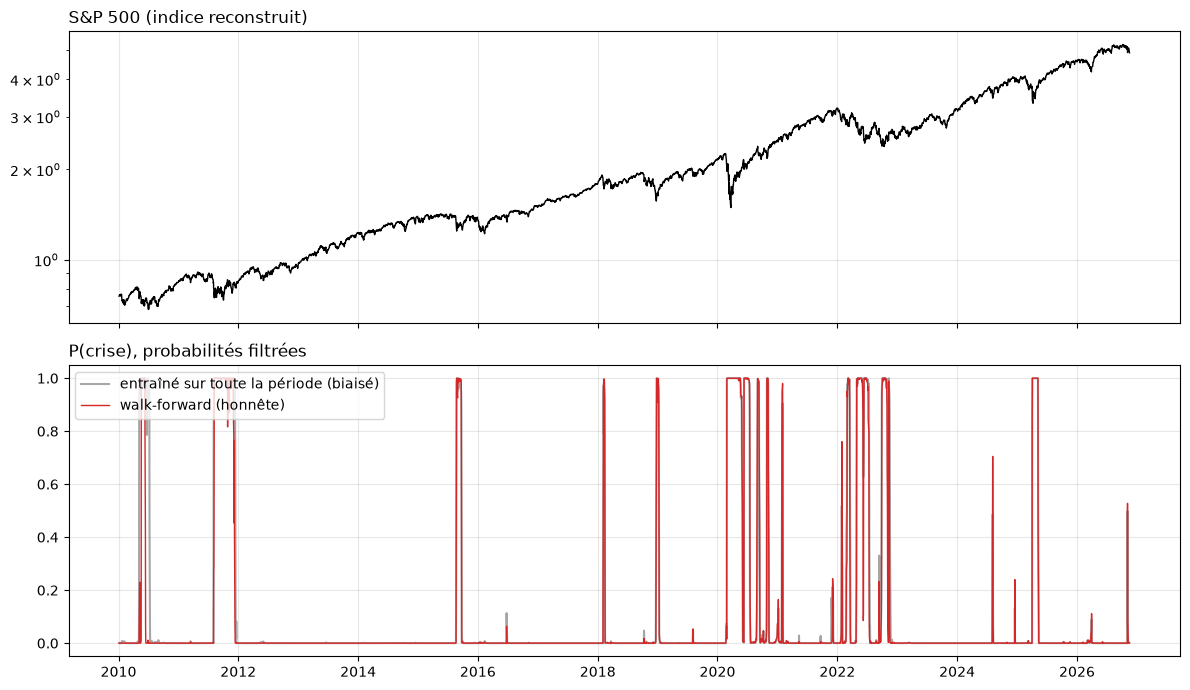

In [6]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 7))

# Indice reconstruit à partir des log-rendements
price = np.exp(df["ret"].cumsum()).loc[probs_wf.index]
axes[0].plot(price.index, price, color="black", linewidth=1)
axes[0].set_yscale("log")
axes[0].set_title("S&P 500 (indice reconstruit)", loc="left")

axes[1].plot(filt_full.index, filt_full["crise"], color="gray", alpha=0.7,
             label="entraîné sur toute la période (biaisé)")
axes[1].plot(probs_wf.index, probs_wf["crise"], color="tab:red", linewidth=1,
             label="walk-forward (honnête)")
axes[1].set_title("P(crise), probabilités filtrées", loc="left")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend(loc="upper left")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

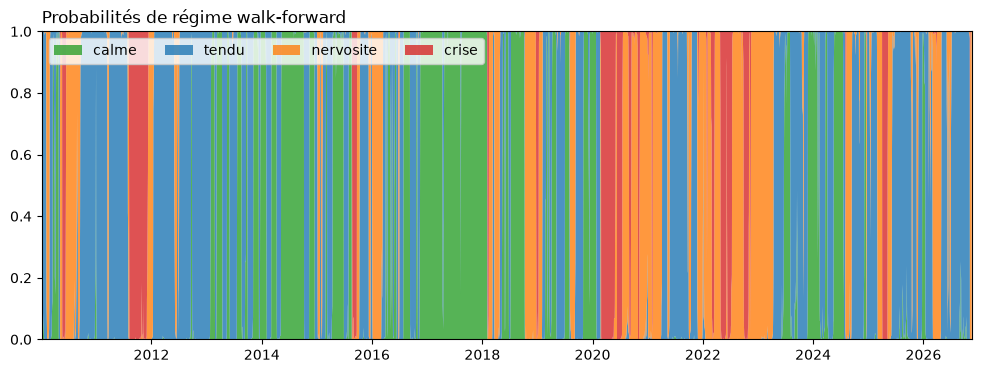

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.stackplot(probs_wf.index, probs_wf.T.values, labels=STATE_NAMES,
             colors=["tab:green", "tab:blue", "tab:orange", "tab:red"], alpha=0.8)
ax.set_ylim(0, 1)
ax.set_title("Probabilités de régime walk-forward", loc="left")
ax.legend(loc="upper left", ncol=4)
ax.margins(x=0)
plt.show()

## Ce qu'il faut retenir

- **Les deux courbes sont très proches** : le modèle walk-forward détecte les mêmes épisodes de crise (2011, 2015, 2018, 2020, 2022, 2025). Les résultats ne venaient donc pas du biais d'entraînement : le modèle est robuste.
- **Mai 2010 (flash crash)** est la principale différence : le modèle de 2010, entraîné sur 2000–2009, a déjà vu 2008, et un choc plus court lui paraît moins grave. La notion de « crise » dépend de ce que le modèle a déjà vu.
- Les probabilités sauvegardées dans `probs_walkforward.parquet` sont **honnêtes** : chaque valeur n'utilise que des données disponibles ce jour-là. On peut les backtester.